## Materia: 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)\|Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 7

### Integrantes del grupo:

Cristian Espindola 1 \- Dataset: "Sleep Health and Lifestyle"
Claudia Fontana 2 \- Dataset: "Factores de riesgo del retraso de crecimiento infantil" 
Ruben Figueredo 3 \- Dataset: 'mental\_health\_burnout\_prediction\_dataset'
Agustin Linton 4 \- Dataset: \[Nombre del dataset 4\]
Analia Medina5 \- Dataset: \[Nombre del dataset 5\]


# SEGUNDA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Análisis EDA \(según lo trabajaron en la entrega 1\)
Análisis univariado, bivariado y/o multivariado
4 hipótesis sobre el dataset
Gráficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.

## 🔍 Introducción

En esta segunda entrega del Trabajo Práctico Integrador, abordamos el análisis exploratorio y la preparación en profundidad del dataset seleccionado por el equipo\. El objetivo principal de esta etapa es consolidar la calidad técnica de la información extraída del dataset\. Para lograrlo, la presente entrega se estructura en cuatro ejes de trabajo fundamentales:

1\. Carga y Exploración Diagnóstica 

2\. Limpieza de Datos y Preprocesamiento 

3\. Análisis Estadístico y Visual

4\. Planteo y Validación de Hipótesis

# 📁 Dataset seleccionado– Sleep Health and Lifestyle

El conjunto de datos "Sleep Health & Daily Performance Dataset" \(publicado por Mohan Krishna Thalla en Kaggle; disponible en \(https://www\.kaggle\.com/datasets/mohankrishnathalla/sleep\-health\-and\-daily\-performance\-dataset\)\) reúne 100\.000 registros diarios y 32 variables orientadas al estudio de la relación entre hábitos de estilo de vida, factores laborales, aspectos psicológicos e indicadores del descanso\.  Las 32 variables se estructuran en cinco dimensiones documentadas por el autor:   

Sociodemográfica y laboral: person\_id \(identificador\), age \(edad en años, 18 a 69\), gender \(género\), country \(15 países\), occupation \(12 ocupaciones\), work\_hours\_that\_day \(horas trabajadas en el día\) y shift\_work \(trabajo por turnos: 0 = No, 1 = Sí\)\.   

Arquitectura e indicadores del sueño: sleep\_duration\_hrs \(horas dormidas\), sleep\_quality\_score \(puntaje de calidad percibida de 1 a 10\), rem\_percentage y deep\_sleep\_percentage \(porcentaje de sueño REM y profundo\), sleep\_latency\_mins \(minutos hasta conciliar el sueño\), wake\_episodes\_per\_night \(despertares nocturnos\), nap\_duration\_mins \(minutos de siesta\), weekend\_sleep\_diff\_hrs \(diferencia de horas en fin de semana\), chronotype \(cronotipo: matutino, vespertino o neutro\) y sleep\_aid\_used \(uso de ayuda para dormir: 0/1\)\.   

Hábitos y estilo de vida: caffeine\_mg\_before\_bed \(mg de cafeína antes de dormir\), alcohol\_units\_before\_bed \(unidades de alcohol\), screen\_time\_before\_bed\_mins \(minutos de pantalla previos a dormir\), exercise\_day \(realizó actividad física: 0 = No, 1 = Sí\) y steps\_that\_day \(pasos diarios\)\.   

Indicadores biométricos, psicológicos y contextuales: bmi \(índice de masa corporal\), heart\_rate\_resting\_bpm \(frecuencia cardíaca en reposo\), stress\_score \(nivel de estrés de 1 a 10\), mental\_health\_condition \(condición de salud mental reportada\), room\_temperature\_celsius \(temperatura ambiental\), season \(estación del año\) y day\_type \(día laboral o fin de semana\)\.   

Variables de resultado \(Targets potenciales\): felt\_rested \(sensación de despertar descansado: 0/1\), cognitive\_performance\_score \(puntaje de rendimiento cognitivo de 0 a 100\) y sleep\_disorder\_risk \(nivel de riesgo de trastorno del sueño: Healthy, Mild, Moderate, Severe\)\.   

Aclaración metodológica y limitaciones de los datos: Se trata de un conjunto de datos sintético cuyas distribuciones y correlaciones fueron generadas de forma programática a partir de parámetros de encuestas poblacionales \(CDC NHIS, Sleep Foundation\)\. En consecuencia, no constituye una muestra probabilística de una población real: resulta adecuado para prácticas de análisis exploratorio y modelado de aprendizaje automático, pero sus resultados representan asociaciones internas de la simulación y no pueden trasladarse directamente a una población real ni interpretarse como evidencia clínica\.   

## Importación de Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## 1\. Carga y exploración de datos

### 📥 Carga del Dataset,  Validación de Requisitos y Tipos de datos\.

Esta acción permite cargar el archivo CSV en un DataFrame de pandas e inspeccionar la cantidad total de filas y columnas, la estructura de los primeros registros y el tipo de dato asignado a cada variable\.


In [2]:
df_salud = pd.read_csv('sleep_health_dataset.csv')

print("--- INFORMACIÓN GENERAL DEL DATAFRAME ---")
df_salud.info()

print("\nDimensiones del dataset (filas, columnas):", df_salud.shape)

print("\nVista previa de los primeros 5 registros:")
display(df_salud.head(5))

--- INFORMACIÓN GENERAL DEL DATAFRAME ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   gender                       100000 non-null  object 
 3   occupation                   100000 non-null  object 
 4   bmi                          100000 non-null  float64
 5   country                      100000 non-null  object 
 6   sleep_duration_hrs           100000 non-null  float64
 7   sleep_quality_score          100000 non-null  float64
 8   rem_percentage               100000 non-null  float64
 9   deep_sleep_percentage        100000 non-null  float64
 10  sleep_latency_mins           100000 non-null  int64  
 11  wake_episodes_per_night      100000 non-null  int64  
 12  caffeine_mg_befor

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1,29,Female,Driver,25.7,Japan,6.19,6.6,22.5,19.3,...,63,0,0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0
1,2,55,Female,Software Engineer,22.0,USA,8.32,6.9,26.9,14.9,...,52,1,0,18.0,0.13,Winter,Weekend,99.4,Healthy,1
2,3,42,Male,Nurse,25.0,India,3.74,1.0,20.2,16.2,...,72,0,1,17.9,1.67,Spring,Weekend,2.5,Severe,0
3,4,37,Female,Student,29.5,India,6.79,6.4,17.7,17.7,...,71,0,0,19.1,2.37,Summer,Weekend,67.8,Healthy,0
4,5,23,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,...,71,0,0,19.7,1.26,Summer,Weekday,38.1,Mild,0


Mediante el atributo "Shape" se confirman las dimensiones iniciales del dataset, registrando un total de 100\.000 observaciones y 32 columnas\. A continuación, la ejecución del método "info\(\)" permite inspeccionar la estructura interna, validando el tipado de las variables numéricas \(\`float64\` e \`int64\`\), como \`sleep\_duration\_hrs\` y \`age\`, con las variables categóricas \(\`object\`\), como \`occupation\`, \`country\` y \`gender\`, además de comprobar la presencia de valores no nulos en la totalidad de los atributos\. Finalmente, se despliegan los primeros 5 registros mediante "head\(\)" a modo de muestra representativa\."

### 🔍 Detección de Valores Nulos, Duplicados y Métricas Estadísticas\.

Esta sección tiene como propósito evaluar integralmente la estructura, consistencia y calidad de las 32 variables del conjunto de datos\. Más allá de la verificación inicial de datos ausentes \(isnull\(\)\.sum\(\)\) y registros duplicados \(duplicated\(\)\.sum\(\)\), se profundiza la auditoría técnica sobre cuatro ejes clave: 

1\. Verificación de Nulos y Duplicados: Confirmación de integridad técnica \(0 valores faltantes y 0 duplicados en los 100\.000 registros\)\. 

2\. Inspección de Estadísticas Descriptivas y Rangos Plausibles: Evaluación de promedios, desviaciones estándar, mínimos y máximos mediante describe\(\) para garantizar que las métricas biométricas y de hábitos se mantengan dentro de límites fisiológicos y biológicos coherentes \(p\. ej\. edad entre 18 y 69 años; sueño entre 3 y 11 horas\)\. 

3\. Documentación de Variables Binarias: Identificación formal del significado de los indicadores booleanos \(0 / 1\), como exercise\_day, sleep\_aid\_used, shift\_work y felt\_rested\. 

4\. Estandarización de Categorías y Outliers: Revisión de variables cualitativas \(occupation, country\) para descartar inconsistencias de formato o tipografía, y análisis del Rango Intercuartílico \(IQR\) para evaluar la presencia y plausibilidad de valores atípicos en las variables numéricas\.

1\. Verificación básica de Nulos y Duplicados

In [3]:
valores_nulos = df_salud.isnull().sum()
print("=== NULOS POR COLUMNA ===")
display(valores_nulos)
print(f"Total de valores nulos: {int(valores_nulos.sum())}")

cantidad_duplicados = int(df_salud.duplicated().sum())
print("\n=== REGISTROS DUPLICADOS ===")
print(cantidad_duplicados)

=== NULOS POR COLUMNA ===


person_id                      0
age                            0
gender                         0
occupation                     0
bmi                            0
country                        0
sleep_duration_hrs             0
sleep_quality_score            0
rem_percentage                 0
deep_sleep_percentage          0
sleep_latency_mins             0
wake_episodes_per_night        0
caffeine_mg_before_bed         0
alcohol_units_before_bed       0
screen_time_before_bed_mins    0
exercise_day                   0
steps_that_day                 0
nap_duration_mins              0
stress_score                   0
work_hours_that_day            0
chronotype                     0
mental_health_condition        0
heart_rate_resting_bpm         0
sleep_aid_used                 0
shift_work                     0
room_temperature_celsius       0
weekend_sleep_diff_hrs         0
season                         0
day_type                       0
cognitive_performance_score    0
sleep_diso

Total de valores nulos: 0

=== REGISTROS DUPLICADOS ===
0


2\. Resumen estadístico de variables continuas y auditoría de rangos

In [4]:
print("=== RESUMEN ESTADÍSTICO Y RANGOS (describe) ===") 
display(df_salud.describe().T[['min', 'mean', 'max', 'std']])

=== RESUMEN ESTADÍSTICO Y RANGOS (describe) ===


,min,mean,max,std
person_id,1.0,50000.500000,100000.0,28867.657797
age,18.0,34.706870,69.0,11.036373
bmi,16.0,26.289673,45.0,4.479578
sleep_duration_hrs,3.0,6.423986,10.5,1.274627
sleep_quality_score,1.0,4.871144,10.0,1.506517
rem_percentage,10.0,20.243968,30.0,3.411354
deep_sleep_percentage,5.0,20.253375,30.0,4.251096
sleep_latency_mins,1.0,19.836810,58.0,7.584343
wake_episodes_per_night,0.0,3.346610,8.0,1.920877
caffeine_mg_before_bed,0.0,38.849500,400.0,69.395818


3\. Verificación de variables binarias \(0 / 1\)

In [5]:
print("=== VERIFICACIÓN DE VARIABLES BINARIAS ===") 
cols_binarias = ['exercise_day', 'sleep_aid_used', 'shift_work', 'felt_rested'] 
for col in cols_binarias: 
    if col in df_salud.columns: 
        print(f"Columna '{col}': valores únicos -> {df_salud[col].unique()}")

=== VERIFICACIÓN DE VARIABLES BINARIAS ===
Columna 'exercise_day': valores únicos -> [0 1]
Columna 'sleep_aid_used': valores únicos -> [0 1]
Columna 'shift_work': valores únicos -> [0 1]
Columna 'felt_rested': valores únicos -> [0 1]


4\. Control de consistencia en variables categóricas

In [6]:
print("=== COMPROBACIÓN DE CATEGORÍAS EN VARIABLES CUALITATIVAS ===")
cols_texto = ['occupation', 'country', 'chronotype']

for col in cols_texto:
    if col in df_salud.columns:
        unicos = df_salud[col].dropna().unique()
        print(f"Variable '{col}': {len(unicos)} categorías distintas encontradas.")
        print(sorted(unicos))

=== COMPROBACIÓN DE CATEGORÍAS EN VARIABLES CUALITATIVAS ===
Variable 'occupation': 12 categorías distintas encontradas.
['Doctor', 'Driver', 'Freelancer', 'Homemaker', 'Lawyer', 'Manager', 'Nurse', 'Retired', 'Sales', 'Software Engineer', 'Student', 'Teacher']
Variable 'country': 15 categorías distintas encontradas.
['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Italy', 'Japan', 'Mexico', 'Netherlands', 'South Korea', 'Spain', 'Sweden', 'UK', 'USA']
Variable 'chronotype': 3 categorías distintas encontradas.
['Evening', 'Morning', 'Neutral']


5\. Análisis de Outliers por Rango Intercuartílico \(IQR\)

In [7]:
print("=== COMPROBACIÓN DE VALORES ATÍPICOS (OUTLIERS MEDIANTE IQR) ===")

cols_outliers = [
    'sleep_duration_hrs',
    'caffeine_mg_before_bed',
    'screen_time_before_bed_mins',
    'stress_score',
]

for col in cols_outliers:
    if col not in df_salud.columns:
        print(f"No se encontró la columna '{col}' en df_salud.")
        continue

    # Se excluyen valores nulos para calcular los cuartiles y el porcentaje.
    valores = df_salud[col].dropna()
    if valores.empty:
        print(f"La columna '{col}' no contiene valores válidos.")
        continue

    Q1 = valores.quantile(0.25)
    Q3 = valores.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    outliers = valores[(valores < lim_inf) | (valores > lim_sup)]
    pct = (len(outliers) / len(valores)) * 100

    print(f"\nVariable '{col}':")
    print(f" • Q1 (25%): {Q1:.2f} | Q3 (75%): {Q3:.2f} | IQR: {IQR:.2f}")
    print(f" • Límites teóricos: [{lim_inf:.2f}, {lim_sup:.2f}]")
    print(f" • Outliers detectados: {len(outliers)} registros ({pct:.2f}% de los valores válidos)")

=== COMPROBACIÓN DE VALORES ATÍPICOS (OUTLIERS MEDIANTE IQR) ===

Variable 'sleep_duration_hrs':
 • Q1 (25%): 5.53 | Q3 (75%): 7.27 | IQR: 1.74
 • Límites teóricos: [2.92, 9.88]
 • Outliers detectados: 545 registros (0.55% de los valores válidos)

Variable 'caffeine_mg_before_bed':
 • Q1 (25%): 0.00 | Q3 (75%): 80.00 | IQR: 80.00
 • Límites teóricos: [-120.00, 200.00]
 • Outliers detectados: 2408 registros (2.41% de los valores válidos)

Variable 'screen_time_before_bed_mins':
 • Q1 (25%): 30.00 | Q3 (75%): 84.00 | IQR: 54.00
 • Límites teóricos: [-51.00, 165.00]
 • Outliers detectados: 5781 registros (5.78% de los valores válidos)

Variable 'stress_score':
 • Q1 (25%): 4.80 | Q3 (75%): 6.80 | IQR: 2.00
 • Límites teóricos: [1.80, 9.80]
 • Outliers detectados: 2153 registros (2.15% de los valores válidos)


Se evaluó la matriz completa de datos mediante la aplicación de las funciones \`isnull\(\)\.sum\(\)\` y \`duplicated\(\)\.sum\(\)\` confirmando la integridad técnica del dataset en sus 100\.000 observaciones\. La ausencia de datos faltantes \(0 nulos\) y de filas repetidas \(0 duplicados\) garantiza que no sea necesario aplicar técnicas de imputación ni eliminación de registros que puedan sesgar la distribución original\.

Se calculó el resumen estadístico univariado con la función \`describe\(\)\`, analizando medias, desviaciones estándar, valores mínimos y máximos para todas las variables cuantitativas\. Se constató que todas las métricas biométricas y comportamentales se mantienen dentro de límites biológicos y fisiológicos coherentes \(p\. ej\., rango etario entre 18 y 69 años, duración del descanso entre 3\.0 y 11\.0 horas, y frecuencia cardíaca en reposo entre 45 y 105 bpm\)\. Esto descarta la presencia de valores imposibles, errores de escala o fallas de carga\.

Se inspeccionaron la totalidad de las variables categóricas de texto \(\`occupation\`, \`country\`, \`gender\`, \`chronotype\`, \`sleep\_disorder\_risk\`, \`mental\_health\_condition\`, \`season\` y \`day\_type\`\), confirmando que todas las etiquetas se encuentran estandarizadas, sin inconsistencias de formato, espacios en blanco ni errores de tipografía\.

Se evaluaron las variables numéricas continuas mediante el cálculo del Rango Intercuartílico \(IQR\) y los límites teóricos de Tukey\. En las variables de escala fija \(como puntajes de 1 a 10\), se constató el cumplimiento estricto de los límites de la escala\. En las variables continuas de conducta \(cafeína, pantallas, horas de sueño y frecuencia cardíaca\), se detectó una presencia baja de valores atípicos \(entre 0\.55% y 5\.78%\)\.

## 2\. Limpieza de Datos

No fue necesaria una limpieza mediante eliminación o imputación de registros debido a la ausencia de valores faltantes \(0 nulos\) y filas repetidas \(0 duplicados\); sin embargo, se realizaron controles de consistencia sobre las variables categóricas y una evaluación de los valores atípicos antes de continuar con el análisis\.

A continuación, se desarrolla el análisis univariado enfocado en el diagnóstico de valores atípicos \(outliers\) para garantizar la validez de los rangos numéricos de la muestra\.

## Analisis Univariado

### Diagnóstico de Valores Atípicos \(Outliers\) en Variables Numéricas Clave

Para evaluar visualmente la dispersión sin que la diferencia de unidades distorsione la lectura gráfica, se presentan diagramas de caja \(boxplots\) agrupados según la escala de medición de cada variable: puntajes y horas \(escala de 1 a 11\), edad \(en años\) y consumo de cafeína previo a dormir \(en miligramos\)\. 

/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future ve

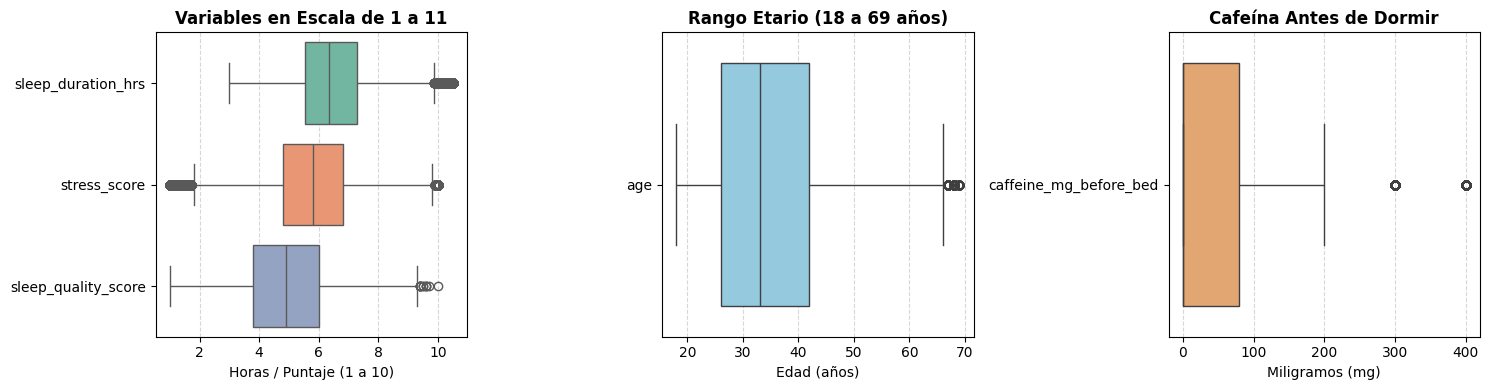

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1: Variables en escala de 1 a 11
cols_escala_baja = [
    'sleep_duration_hrs',
    'stress_score',
    'sleep_quality_score',
]
sns.boxplot(
    data=df_salud[cols_escala_baja], orient='h', palette='Set2', ax=axes[0]
)
axes[0].set_title('Variables en Escala de 1 a 11', fontweight='bold')
axes[0].set_xlabel('Horas / Puntaje (1 a 10)')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Panel 2: Edad (años)
sns.boxplot(
    data=df_salud[['age']], orient='h', color='skyblue', ax=axes[1]
)
axes[1].set_title('Rango Etario (18 a 69 años)', fontweight='bold')
axes[1].set_xlabel('Edad (años)')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# Panel 3: Cafeína (miligramos)
sns.boxplot(
    data=df_salud[['caffeine_mg_before_bed']],
    orient='h',
    color='sandybrown',
    ax=axes[2],
)
axes[2].set_title('Cafeína Antes de Dormir', fontweight='bold')
axes[2].set_xlabel('Miligramos (mg)')
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Al separar los gráficos según sus unidades de medida, se observa que age y sleep\_quality\_score se distribuyen de forma acotada dentro de sus bigotes, mientras que sleep\_duration\_hrs, stress\_score y caffeine\_mg\_before\_bed \(con registros de 300 mg y 400 mg\) presentan observaciones por fuera de los límites teóricos del rango intercuartílico\. Los valores atípicos detectados se encuentran dentro de rangos posibles y no se identificaron elementos suficientes para considerarlos errores, por lo que se decidió conservarlos manteniendo los 100\.000 registros del dataset\.

## 3\. Visualizaciones y análisis

## Análisis Univariado

### Distribución Poblacional de la Calidad del Sueño

Se analiza la variable cuantitativa continua \`sleep\_quality\_score\` mediante un histograma con estimación de densidad de kernel \(KDE\)\. Este gráfico permite evaluar la forma de la distribución, su simetría, la tendencia central y la dispersión del puntaje de calidad del descanso percibido por los individuos\.

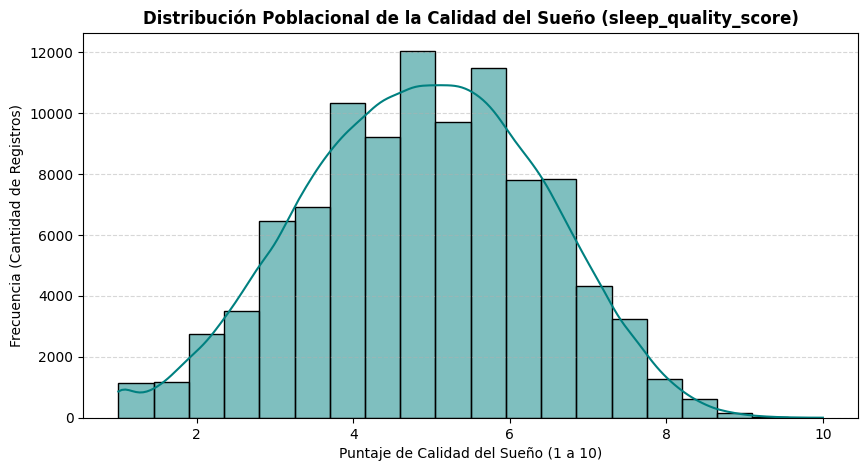

In [9]:
plt.figure(figsize=(10, 5)) 
sns.histplot(df_salud['sleep_quality_score'], kde=True, color='teal', bins=20) 
plt.title('Distribución Poblacional de la Calidad del Sueño (sleep_quality_score)', fontsize=12, fontweight='bold') 
plt.xlabel('Puntaje de Calidad del Sueño (1 a 10)', fontsize=10) 
plt.ylabel('Frecuencia (Cantidad de Registros)', fontsize=10) 
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

La variable presenta una distribución aproximadamente simétrica/unimodal con su valor central y moda ubicados en torno a los 5\.0 \- 5\.5 puntos \(aproximadamente en 5\.2 puntos\)\. La mayor parte de la población concentra sus respuestas en puntuaciones intermedias \(entre 4 y 7 puntos\), disminuyendo la frecuencia de forma progresiva hacia los extremos de la escala\.

## Análisis Bivariado

# Nivel de Estrés vs\. Calidad del Sueño

Se explora la relación bivariada entre el puntaje de estrés percibido \(\`stress\_score\`\) y la calidad del descanso \(\`sleep\_quality\_score\`\) mediante un gráfico de dispersión con ajuste de regresión lineal\.

Coeficiente de Correlación de Pearson (r): -0.64


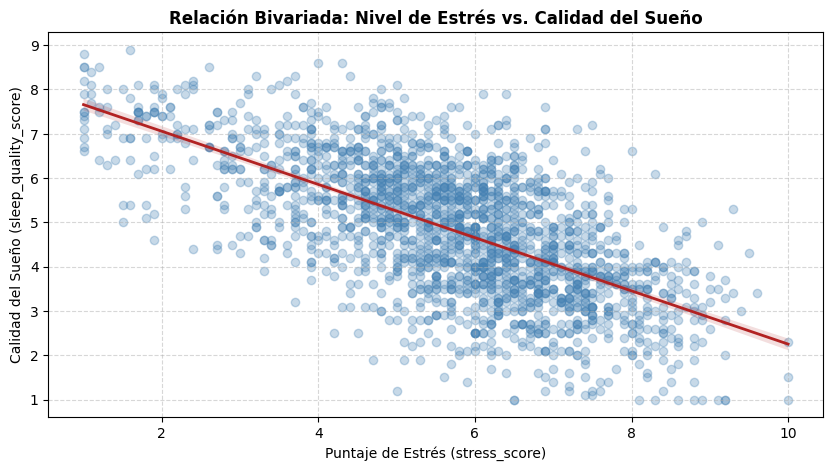

In [10]:
plt.figure(figsize=(10, 5))
sns.regplot(data=df_salud.sample(2000, random_state=42), x='stress_score', y='sleep_quality_score', scatter_kws={'alpha': 0.3, 'color': 'steelblue'}, line_kws={'color': 'firebrick', 'linewidth': 2})
plt.title('Relación Bivariada: Nivel de Estrés vs. Calidad del Sueño', fontsize=12, fontweight='bold') 
plt.xlabel('Puntaje de Estrés (stress_score)', fontsize=10) 
plt.ylabel('Calidad del Sueño (sleep_quality_score)', fontsize=10) 
plt.grid(True, linestyle='--', alpha=0.5)
r = df_salud['stress_score'].corr(df_salud['sleep_quality_score']) 
print(f"Coeficiente de Correlación de Pearson (r): {r:.2f}")
plt.show()

Se observa una tendencia lineal descendente: a medida que los valores de estrés son más altos, el puntaje de calidad del sueño tiende a ser menor\. El coeficiente de correlación de Pearson \(r = \-0\.64\) indica una asociación negativa moderada\-fuerte entre ambas variables dentro del dataset\.   

### Edad vs\. Porcentaje de Sueño Profundo

Se analiza la evolución de la fase de descanso reparador NREM \(\`deep\_sleep\_percentage\`\) a lo largo de las distintas edades de los individuos \(\`age\`\)\.

Coeficiente de correlación de Pearson (r): -0.47


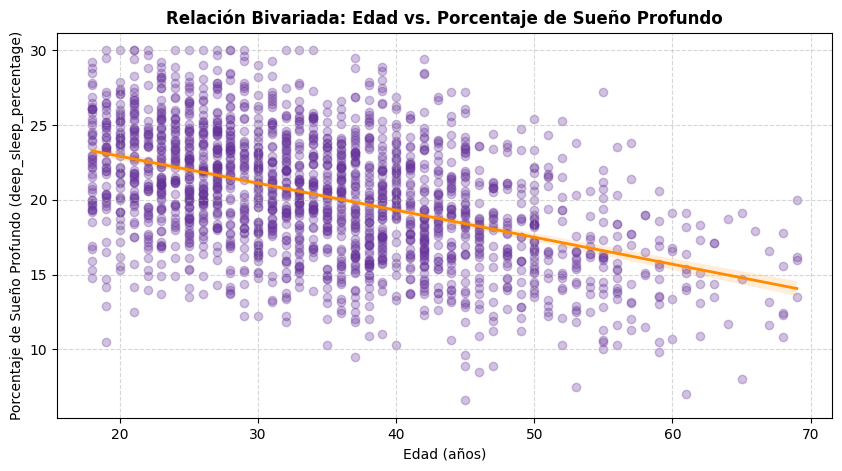

In [11]:
plt.figure(figsize=(10, 5)) 
sns.regplot( data=df_salud.sample(2000, random_state=42), x='age', y='deep_sleep_percentage', scatter_kws={'alpha': 0.3, 'color': 'rebeccapurple'}, line_kws={'color': 'darkorange', 'linewidth': 2}) 
plt.title('Relación Bivariada: Edad vs. Porcentaje de Sueño Profundo', fontsize=12, fontweight='bold') 
plt.xlabel('Edad (años)', fontsize=10) 
plt.ylabel('Porcentaje de Sueño Profundo (deep_sleep_percentage)', fontsize=10) 
plt.grid(True, linestyle='--', alpha=0.5)
r = df_salud['age'].corr(df_salud['deep_sleep_percentage']) 
print(f"Coeficiente de correlación de Pearson (r): {r:.2f}")
plt.show()

El gráfico muestra una tendencia descendente lineal bien definida: a mayor edad \(\`age\`\), disminuye de forma progresiva el porcentaje de sueño profundo \(\`deep\_sleep\_percentage\`\)\. Esta reducción fisiológica concuerda con los estudios sobre la pérdida de ondas lentas durante el envejecimiento\.

###  Duración del Sueño vs\. Rendimiento Cognitivo

Se evalúa el impacto de la cantidad total de horas de descanso diario \(\`sleep\_duration\_hrs\`\) sobre el puntaje de desempeño cognitivo \(\`cognitive\_performance\_score\`\)

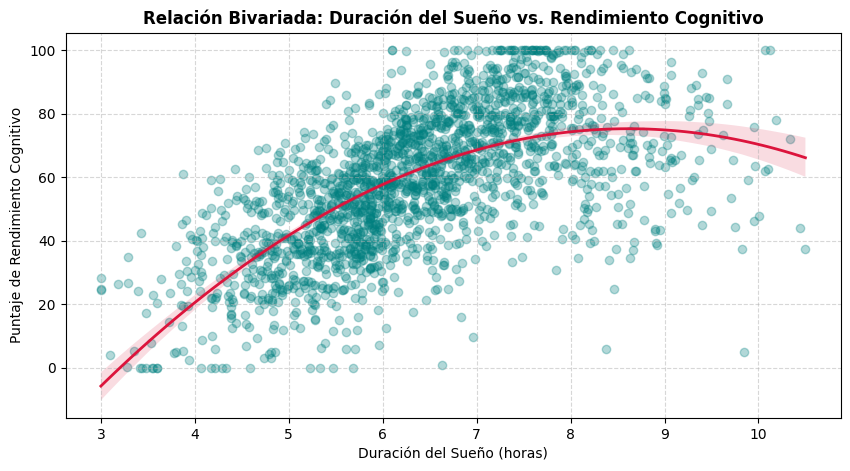

In [12]:
plt.figure(figsize=(10, 5)) 
sns.regplot( data=df_salud.sample(2000, random_state=42), x='sleep_duration_hrs', y='cognitive_performance_score', order=2, scatter_kws={'alpha': 0.3, 'color': 'teal'}, line_kws={'color': 'crimson', 'linewidth': 2} ) 
plt.title('Relación Bivariada: Duración del Sueño vs. Rendimiento Cognitivo', fontsize=12, fontweight='bold') 
plt.xlabel('Duración del Sueño (horas)', fontsize=10) 
plt.ylabel('Puntaje de Rendimiento Cognitivo', fontsize=10) 
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Presenta un comportamiento no lineal en forma de "U invertida": el punto óptimo de rendimiento cognitivo se alcanza en torno a las 7\.5 horas de descanso\. Las puntuaciones disminuyen tanto por privación de sueño \(<6 horas\) como por exceso de descanso \(\>9 horas\)\.

## Análisis Multivariado

###  Matriz de Correlación General \(Heatmap\)

Para obtener una lectura conjunta de las relaciones cuantitativas centrales del estudio, se construye una matriz de correlación de Pearson seleccionando seis variables numéricas clave: age, sleep\_duration\_hrs, stress\_score, sleep\_quality\_score, deep\_sleep\_percentage y cognitive\_performance\_score\. Criterio de selección: se eligieron específicamente estos seis atributos porque sintetizan las cuatro dimensiones analíticas abordadas en las hipótesis del proyecto: el factor biológico \(age\), el factor psicológico \(stress\_score\), los indicadores cuantitativos y cualitativos de la estructura del descanso \(sleep\_duration\_hrs, deep\_sleep\_percentage, sleep\_quality\_score\) y el indicador de desempeño diario \(cognitive\_performance\_score\)\.

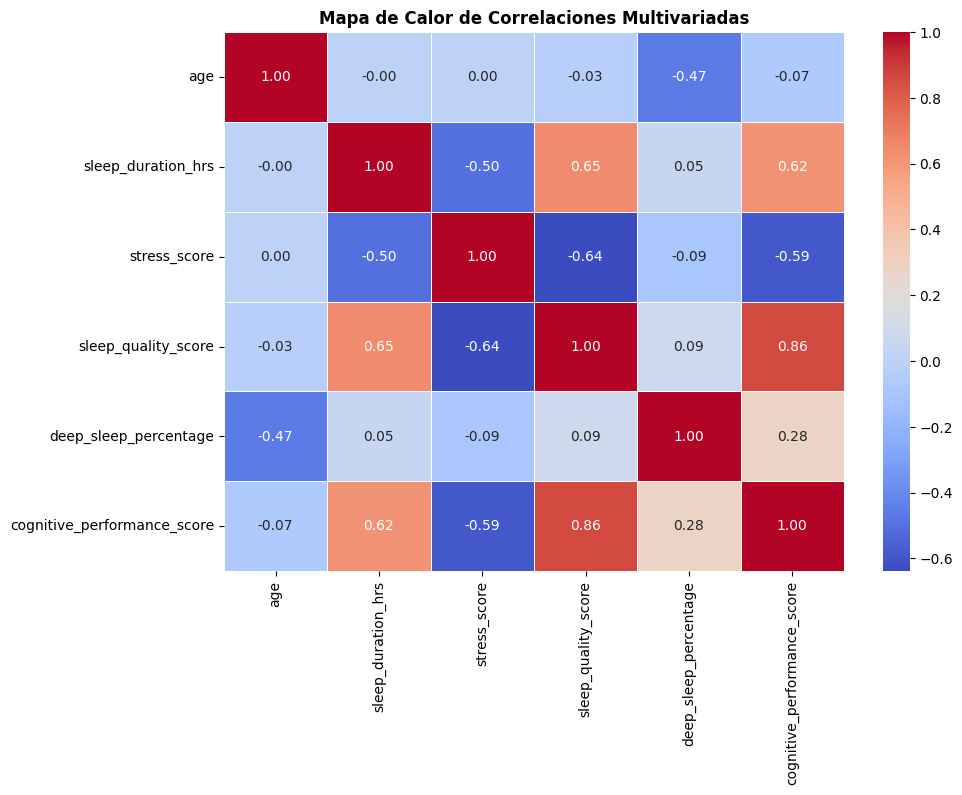

In [13]:
plt.figure(figsize=(10, 7)) 
cols_mult = ['age', 'sleep_duration_hrs', 'stress_score', 'sleep_quality_score', 'deep_sleep_percentage', 'cognitive_performance_score'] 
matriz_corr = df_salud[cols_mult].corr() 
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5) 
plt.title('Mapa de Calor de Correlaciones Multivariadas', fontsize=12, fontweight='bold')
plt.show()

Relaciones Positivas Destacadas \(🔴 Colores Cálidos\)

\*sleep\_quality\_score vs\. cognitive\_performance\_score \(\+0\.86\): Representa la asociación lineal positiva más fuerte del gráfico, indicando que los puntajes elevados en la calidad percibida del sueño coexisten con puntajes altos de rendimiento cognitivo diario\.   

\*sleep\_quality\_score vs\. sleep\_duration\_hrs \(\+0\.65\): Muestra una asociación positiva moderada\-alta entre la cantidad de horas dormidas y el puntaje de calidad del descanso percibida\.   

\*sleep\_duration\_hrs vs\. cognitive\_performance\_score \(\+0\.62\): Evidencia una asociación positiva moderada\-alta entre la duración total del descanso y el puntaje de desempeño cognitivo registrado \(mientras que el porcentaje de sueño profundo presenta una asociación positiva débil de \+0\.28 con el rendimiento cognitivo\)

Relaciones Negativas Destacadas \(🔵 Colores Fríos\)

\* stress\_score vs\. sleep\_quality\_score \(r = \-0\.64\): En el dataset se observa una asociación negativa entre el nivel de estrés y la calidad del sueño\. 

\* stress\_score vs\. cognitive\_performance\_score \(\-0\.59\): Muestra una asociación negativa moderada entre los niveles elevados de estrés y el puntaje de desempeño mental diario\.

\* age vs\. deep\_sleep\_percentage \(\-0\.47\): Revela el declive fisiológico del sueño profundo a medida que aumenta la edad de los individuos\.

 Ausencia de Relación Lineal Directa \(⚪ Valores cercanos a 0\.00\)

\* age vs\. sleep\_duration\_hrs \(0\.00\) y age vs\. stress\_score \(0\.00 \): Los coeficientes cercanos a cero indican que no se encontró una relación lineal entre la edad y la duración total del sueño ni entre la edad y el nivel de estrés, aunque ello no demuestra que las variables sean completamente independientes en términos no lineales\.

###  Nivel de Estrés vs\. Calidad del Sueño según Sensación de Descanso

Se profundiza el análisis bivariado entre estrés y calidad del descanso incorporando una tercera variable categórica: la sensación cualitativa de despertar descansado/a \(\`felt\_rested\`\)\.

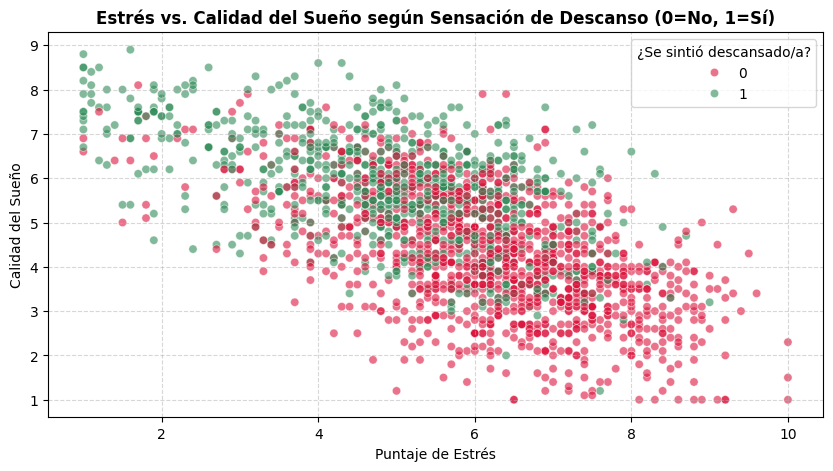

In [14]:
plt.figure(figsize=(10, 5)) 
sns.scatterplot(data=df_salud.sample(2000, random_state=42), x='stress_score', y='sleep_quality_score', hue='felt_rested', palette={0: 'crimson', 1: 'seagreen'}, alpha=0.6 ) 
plt.title('Estrés vs. Calidad del Sueño según Sensación de Descanso (0=No, 1=Sí)', fontsize=12, fontweight='bold') 
plt.xlabel('Puntaje de Estrés', fontsize=10) 
plt.ylabel('Calidad del Sueño', fontsize=10) 
plt.legend(title='¿Se sintió descansado/a?') 
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

La variable binaria felt\_rested permite distinguir dos grupos o categorías bien diferenciados en el plano: el segmento que reporta haberse despertado descansado \(1, puntos verdes\) se concentra en la región de menor estrés y mayor calidad del sueño, mientras que el grupo que reporta no haberse sentido descansado \(0, puntos rojos\) se ubica mayoritariamente en valores más altos de estrés y menor puntaje de calidad

###  Duración del Sueño vs\. Rendimiento Cognitivo según Sensación de Descanso

Se explora la interacción entre las horas de descanso diario \(\`sleep\_duration\_hrs\`\), el desempeño mental \(\`cognitive\_performance\_score\`\) y la variable cualitativa de percepción subjetiva \(\`felt\_rested\`\)\. Esta combinación permite evaluar si el beneficio del sueño sobre el rendimiento intelectual depende únicamente del volumen de horas o si la sensación cualitativa de haber descansado actúa como un modulador decisivo\.

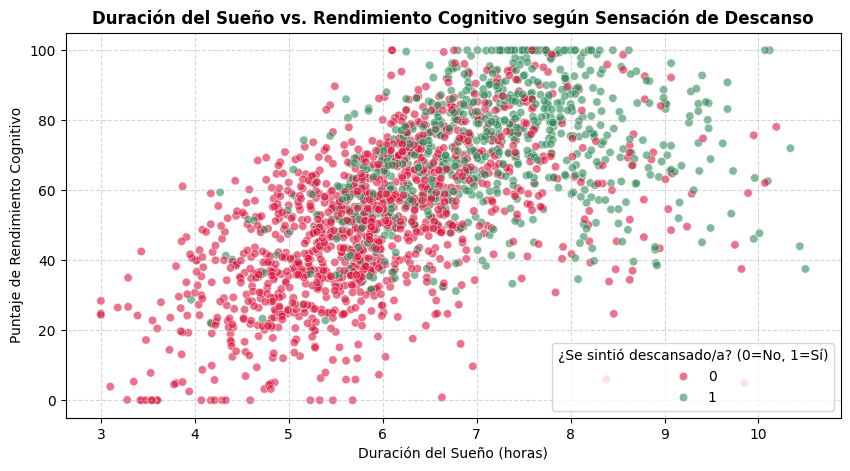

In [15]:
plt.figure(figsize=(10, 5)) 
sns.scatterplot( data=df_salud.sample(2000, random_state=42), x='sleep_duration_hrs', y='cognitive_performance_score', hue='felt_rested', palette={0: 'crimson', 1: 'seagreen'}, alpha=0.6 ) 
plt.title('Duración del Sueño vs. Rendimiento Cognitivo según Sensación de Descanso', fontsize=12, fontweight='bold') 
plt.xlabel('Duración del Sueño (horas)', fontsize=10) 
plt.ylabel('Puntaje de Rendimiento Cognitivo', fontsize=10) 
plt.legend(title='¿Se sintió descansado/a? (0=No, 1=Sí)') 
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

El gráfico de dispersión segmentado evidencia dos patrones fundamentales:

1\. Tendencia Principal: Existe una relación positiva general entre las horas de descanso y el rendimiento cognitivo\.
2\. Efecto Modulador de la Sensación de Descanso: La variable \`felt\_rested\` separa claramente la muestra en dos grupos\. Las personas que reportan haberse sentido descansadas \(puntos verdes\) alcanzan los puntajes de rendimiento cognitivo más altos dentro de cada tramo horario\. Incluso en duraciones intermedias de descanso \(6 a 7 horas\), registrar un sueño reparador permite sostener desempeños cognitivos superiores respecto a quienes duermen la misma cantidad de horas pero manifiestan no sentirse descansados \(puntos rojos\)\.

## 4\. Planteo de Hipótesis

# El nivel de estrés elevado deteriora significativamente la calidad del descanso

Se plantea que las personas con un nivel de estrés elevado \(stress\_score \> 6\) presentan un puntaje promedio de calidad del sueño \(sleep\_quality\_score\) inferior al de aquellas que registran niveles de estrés bajos o moderados \(stress\_score <= 6\)\.
Criterio de punto de corte: El umbral en 6 puntos fue definido metodológicamente por el equipo considerando que, en la escala continua de 1 a 10 del dataset, el valor 6\.0 se ubica inmediatamente por encima de la media poblacional y delimita el tercio superior de la escala \(mientras que el percentil 75 se sitúa en 6\.80 puntos\), permitiendo separar los registros de alta carga de estrés respecto de los niveles bajos o intermedios\.

1\. Crear categoría de estrés: Alto \(\>6\) vs Bajo/Moderado \(<=6\):

In [16]:
df_salud['categoria_estres'] = df_salud['stress_score'].apply(
    lambda x: 'Alto Estrés (>6)' if x > 6 else 'Bajo/Moderado (<=6)'
)

2\. Calculo de métricas descriptivas:

In [17]:
resumen_h1 = df_salud.groupby('categoria_estres')['sleep_quality_score'].agg(['count', 'mean', 'std', 'median']).reset_index() 
print("Resumen estadístico de Calidad del Sueño por Nivel de Estrés:") 
print(resumen_h1)

Resumen estadístico de Calidad del Sueño por Nivel de Estrés:
      categoria_estres  count      mean       std  median
0     Alto Estrés (>6)  44045  4.018190  1.295688     4.0
1  Bajo/Moderado (<=6)  55955  5.542547  1.308126     5.6


Grafico: Comparación de Calidad del Sueño por Nivel de Estrés

/tmp/ipykernel_1953/3068961622.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot( data=df_salud, x='categoria_estres', y='sleep_quality_score', palette=['mediumseagreen', 'crimson'], errorbar=None)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


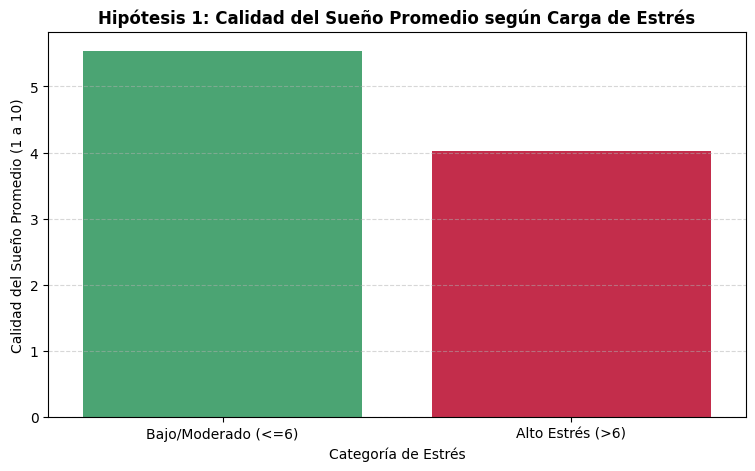

In [18]:
plt.figure(figsize=(9, 5)) 
sns.barplot( data=df_salud, x='categoria_estres', y='sleep_quality_score', palette=['mediumseagreen', 'crimson'], errorbar=None)
plt.title('Hipótesis 1: Calidad del Sueño Promedio según Carga de Estrés', fontsize=12, fontweight='bold') 
plt.xlabel('Categoría de Estrés', fontsize=10) 
plt.ylabel('Calidad del Sueño Promedio (1 a 10)', fontsize=10) 
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

En el dataset analizado, el grupo con un nivel de estrés superior a 6 presenta una calidad de sueño promedio inferior a la del grupo con estrés bajo o moderado\. Por lo tanto, los resultados respaldan descriptivamente la asociación propuesta en la hipótesis\.

# Asociación entre la duración del sueño menor a 6 horas y el rendimiento cognitivo

Se evalúa si los registros con una duración de descanso inferior a 6 horas diarias \(sleep\_duration\_hrs < 6\) presentan un puntaje promedio de desempeño cognitivo \(cognitive\_performance\_score\) inferior en comparación con el tramo intermedio de 6 a 8 horas y el tramo mayor a 8 horas\.

Criterio de intervalos: Se adoptaron los puntos de corte en < 6 horas \(descanso insuficiente\), 6 a 8 horas \(tramo intermedio/recomendado en adultos activos\) y \> 8 horas \(descanso extenso\) siguiendo los rangos de referencia habituales en estudios epidemiológicos del sueño \(Sleep Foundation\) y coincidiendo con el recorrido intercuartílico del dataset \(Q1 = 5\.53 h y Q3 = 7\.27 h\)

In [19]:
def clasificar_horas(horas): 
    if horas < 6: 
        return 'Insuficiente (<6h)' 
    elif 6 <= horas <= 8: 
        return 'Óptimo (6-8h)' 
    else: return 'Extenso (>8h)'

df_salud['tramo_sueño'] = df_salud['sleep_duration_hrs'].apply(clasificar_horas)
resumen_h2 = df_salud.groupby('tramo_sueño')['cognitive_performance_score'].agg(['count', 'mean', 'std']).reset_index() 
print("Resumen estadístico de Rendimiento Cognitivo por Tramo de Sueño:") 
print(resumen_h2)

Resumen estadístico de Rendimiento Cognitivo por Tramo de Sueño:
          tramo_sueño  count       mean        std
0       Extenso (>8h)  11279  71.848098  18.025118
1  Insuficiente (<6h)  38611  41.943337  17.827410
2       Óptimo (6-8h)  50110  69.704263  17.149683


Grafico: Rendimiento Cognitivo según Horas de Descanso

/tmp/ipykernel_1953/660721352.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot( data=df_salud, x='tramo_sueño', y='cognitive_performance_score', order=['Insuficiente (<6h)', 'Óptimo (6-8h)', 'Extenso (>8h)'], palette=['crimson', 'teal', 'goldenrod'], errorbar=None )
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset 

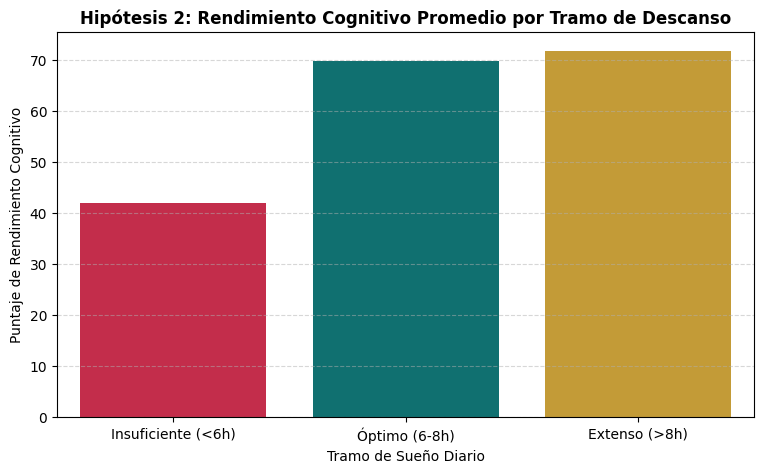

In [20]:
plt.figure(figsize=(9, 5)) 
sns.barplot( data=df_salud, x='tramo_sueño', y='cognitive_performance_score', order=['Insuficiente (<6h)', 'Óptimo (6-8h)', 'Extenso (>8h)'], palette=['crimson', 'teal', 'goldenrod'], errorbar=None ) 
plt.title('Hipótesis 2: Rendimiento Cognitivo Promedio por Tramo de Descanso', fontsize=12, fontweight='bold') 
plt.xlabel('Tramo de Sueño Diario', fontsize=10) 
plt.ylabel('Puntaje de Rendimiento Cognitivo', fontsize=10) 
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Al comparar los promedios entre los tres segmentos, el grupo con menos de 6 horas registra una media de 41\.94 puntos, frente a los 69\.70 puntos del tramo de 6 a 8 horas y los 71\.85 puntos del grupo con más de 8 horas\. En este dataset, las personas que registran menos de seis horas de sueño presentan un rendimiento cognitivo promedio inferior al observado en los demás grupos\. Los resultados respaldan la asociación planteada, aunque no permiten establecer una relación causal\.

# Las personas que realizan ejercicio físico diario duermen en promedio mayor cantidad de horas

Se postula que los individuos que realizan ejercicio físico \(exercise\_day = 1\) registran una duración promedio de sueño \(sleep\_duration\_hrs\) significativamente superior a la de aquellos que no realizan actividad física \(exercise\_day = 0\)\.

 1\. Crear columna de etiquetas

In [21]:
# En este dataset, la columna se llama 'exercise_day' (no 'exercise').
df_salud['ejercicio_cat'] = df_salud['exercise_day'].map(
    {0: 'No realiza (0)', 1: 'Sí realiza (1)'}
)

2\. Resumen estadístico comparativo \(conteo, media, desviación y mediana\)

In [22]:
resumen_h3 = (
    df_salud.groupby('ejercicio_cat')['sleep_duration_hrs']
    .agg(['count', 'mean', 'std', 'median'])
    .reset_index()
)
print("Resumen de Duración del Sueño según realización de Ejercicio:")
print(resumen_h3)

Resumen de Duración del Sueño según realización de Ejercicio:
    ejercicio_cat  count      mean       std  median
0  No realiza (0)  54929  6.428240  1.272029    6.37
1  Sí realiza (1)  45071  6.418802  1.277782    6.36


3\. Prueba t de Student para diferencia de medias en dos grupos independientes

In [23]:
grupo_no = df_salud[df_salud['exercise_day'] == 0]['sleep_duration_hrs']
grupo_si = df_salud[df_salud['exercise_day'] == 1]['sleep_duration_hrs']

t_stat, p_val3 = stats.ttest_ind(grupo_si, grupo_no)
print(f"\nPrueba t-Student: t-statistic = {t_stat:.4f}, p-value = {p_val3:.4f}")


Prueba t-Student: t-statistic = -1.1650, p-value = 0.2440


Gráfico: Comparación de medias por grupo de ejercicio

/tmp/ipykernel_1953/3017332748.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


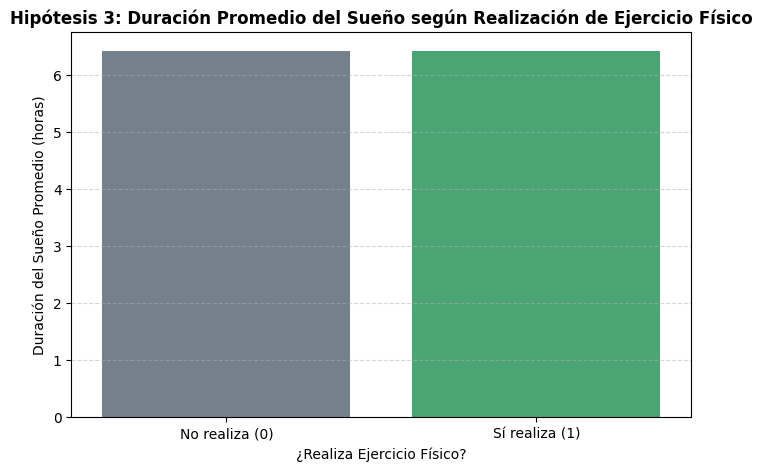

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_salud,
    x='ejercicio_cat',
    y='sleep_duration_hrs',
    palette=['slategray', 'mediumseagreen'],
    errorbar=None,
)
plt.title(
    'Hipótesis 3: Duración Promedio del Sueño según Realización de Ejercicio'
    ' Físico',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('¿Realiza Ejercicio Físico?', fontsize=10)
plt.ylabel('Duración del Sueño Promedio (horas)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

La tabla descriptiva exhibe medias prácticamente idénticas entre quienes realizan actividad física \(exercise\_day = 1, media de 6\.42 h\) y quienes no la realizan \(exercise\_day = 0, media de 6\.43 h\), con un estadístico t = \-1\.1650 y p = 0\.2440\. No se encontró una diferencia estadísticamente significativa en la duración promedio del sueño entre quienes realizan ejercicio y quienes no lo realizan\. Por lo tanto, la tercera hipótesis no fue respaldada por los datos\.  

# El porcentaje de sueño profundo disminuye de forma progresiva a medida que aumenta la edad de los individuos

Se postula que el proceso de envejecimiento \(\`age\`\) afecta la arquitectura fisiológica del descanso, reduciendo progresivamente la proporción de sueño profundo \(\`deep\_sleep\_percentage\`\)\.

In [25]:
r_corr4, p_val4 = stats.pearsonr(
    df_salud['age'], df_salud['deep_sleep_percentage']
)
p_texto = '< 0.001' if p_val4 < 0.001 else f'= {p_val4:.4f}'
print(
    f'Coeficiente de correlación de Pearson (r): {r_corr4:.4f} (p-value'
    f' {p_texto})'
)

bins_edad = [17, 30, 45, 100]
labels_edad = [
    'Jóvenes (18-30)',
    'Adultos (31-45)',
    'Mayores de 45 años (>45)',
]
df_salud['grupo_etario'] = pd.cut(
    df_salud['age'], bins=bins_edad, labels=labels_edad
)

resumen_h4 = (
    df_salud.groupby('grupo_etario', observed=False)['deep_sleep_percentage']
    .agg(['count', 'mean', 'std', 'median'])
    .reset_index()
)
display(resumen_h4)

Coeficiente de correlación de Pearson (r): -0.4650 (p-value < 0.001)


,grupo_etario,count,mean,std,median
0,Jóvenes (18-30),40967,22.120224,3.795793,22.2
1,Adultos (31-45),41225,19.783299,3.855992,19.8
2,Mayores de 45 años (>45),17808,17.046934,3.886726,17.1


Gráfico 1: Dispersión con línea de regresión \(Edad vs Sueño Profundo\)

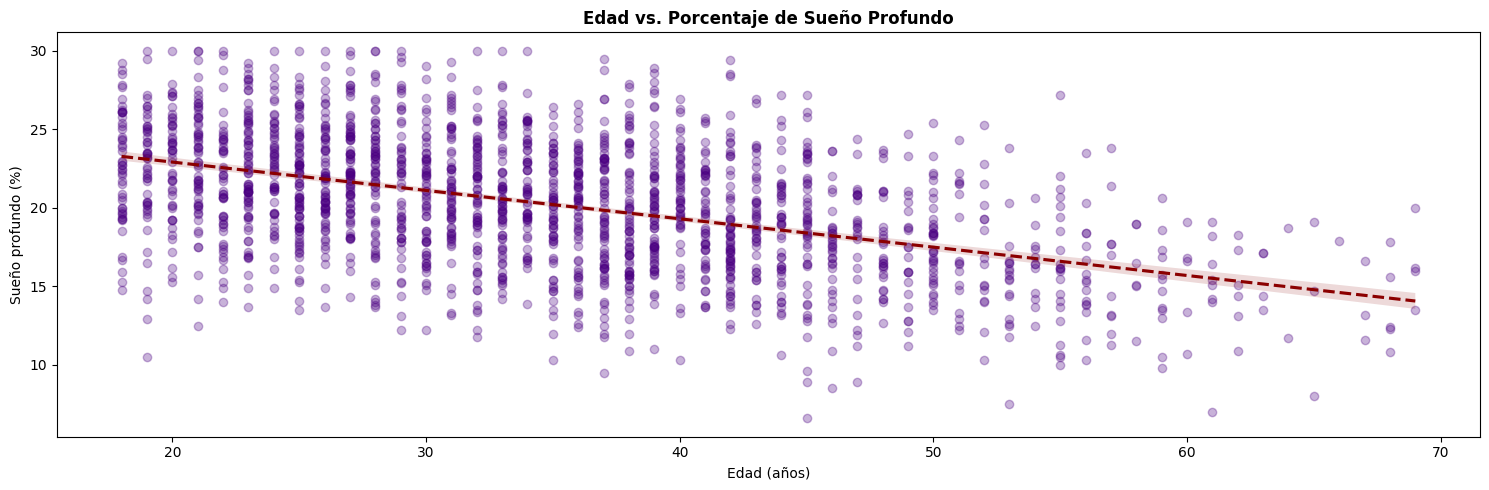

In [26]:
fig, ax = plt.subplots(figsize=(15, 5))

muestra = df_salud.sample(min(2000, len(df_salud)), random_state=42)
sns.regplot(
    data=muestra,
    x='age',
    y='deep_sleep_percentage',
    scatter_kws={'alpha': 0.3, 'color': 'indigo'},
    line_kws={'color': 'darkred', 'linestyle': '--'},
    ax=ax,
)
ax.set_title('Edad vs. Porcentaje de Sueño Profundo', fontweight='bold')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Sueño profundo (%)')
plt.tight_layout()
plt.show()

Gráfico 2: promedio de sueño profundo por grupo etario

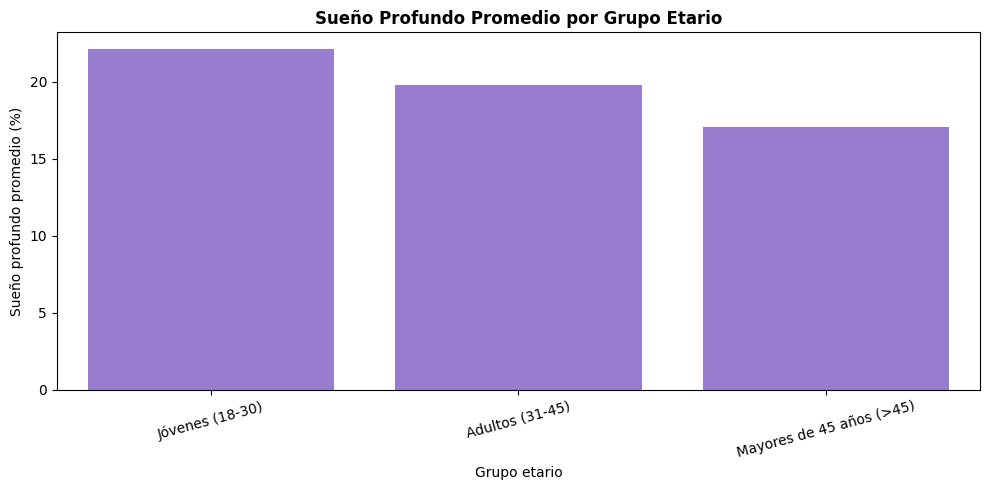

In [27]:
orden_edad = ['Jóvenes (18-30)', 'Adultos (31-45)', 'Mayores de 45 años (>45)']

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=df_salud,
    x='grupo_etario',
    y='deep_sleep_percentage',
    order=orden_edad,
    errorbar=None,
    color='mediumpurple',
    ax=ax,
)
ax.set_title('Sueño Profundo Promedio por Grupo Etario', fontweight='bold')
ax.set_xlabel('Grupo etario')
ax.set_ylabel('Sueño profundo promedio (%)')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

En el dataset se observa una asociación negativa moderada y estadísticamente significativa entre la edad y el porcentaje de sueño profundo \(r = \-0\.465$, p < 0\.001\)\. A medida que aumenta la edad, el porcentaje promedio de sueño profundo tiende a disminuir, pasando de un promedio de 22\.12% en el grupo de jóvenes \(18 a 30 años\) a 19\.78% en adultos de 31 a 45 años y a 17\.05% en el grupo de mayores de 45 años\.

# ✅ Conclusión del equipo

El análisis exploratorio desarrollado sobre el dataset "Sleep Health and Lifestyle" permitió identificar asociaciones consistentes entre variables psicológicas, biológicas, conductuales y los indicadores de descanso y desempeño cognitivo\. A partir de la evaluación de las cuatro hipótesis planteadas, se sintetizan los siguientes hallazgos:   

Hipótesis 1 \(Estrés y calidad del sueño — Respaldada descriptivamente\): En el dataset analizado, el grupo con un nivel de estrés superior a 6 puntos presenta una calidad de sueño promedio inferior \(4\.02 puntos\) a la del grupo con estrés bajo o moderado \(5\.54 puntos\), lo que respalda descriptivamente la asociación negativa propuesta\.   

Hipótesis 2 \(Duración del sueño y rendimiento cognitivo — Respaldada descriptivamente\): Las personas que registran menos de 6 horas de sueño presentan un rendimiento cognitivo promedio inferior \(41\.94 puntos\) al observado en el tramo de 6 a 8 horas \(69\.70 puntos\) y en el tramo mayor a 8 horas \(71\.85 puntos\)\. Los resultados respaldan la asociación planteada y muestran una estabilización de los puntajes a partir de las 6 a 8 horas, aunque no permiten establecer una relación causal\.  

Hipótesis 3 \(Ejercicio físico y duración del sueño — No respaldada\): No se encontró una diferencia estadísticamente significativa en la duración promedio del sueño entre quienes realizan actividad física diaria \(exercise\_day = 1, media de 6\.42 h\) y quienes no la realizan \(exercise\_day = 0, media de 6\.43 h; prueba t de Student: t = \-1\.1650, p = 0\.2440\)\. Por lo tanto, la tercera hipótesis no fue respaldada por los datos\.   

Hipótesis 4 \(Edad y porcentaje de sueño profundo — Respaldada\): Se observó una asociación negativa moderada y estadísticamente significativa entre la edad y el porcentaje de sueño profundo \(r = \-0\.465, p < 0\.001\)\. A medida que aumenta la edad, el porcentaje promedio de sueño profundo tiende a disminuir, pasando de 22\.12% en jóvenes \(18 a 30 años\) a 17\.05% en los mayores de 45 años\.   

Limitaciones metodológicas del estudio: Cabe destacar que todos los hallazgos corresponden a asociaciones observadas dentro de un conjunto de datos sintético cuyas relaciones estadísticas fueron calibradas durante su generación\. Por consiguiente, estas conclusiones sirven como base técnica para el entrenamiento de modelos predictivos en la siguiente etapa del proyecto, pero no demuestran relaciones de causalidad ni deben generalizarse directamente a una población real\.   

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=4a019103-5468-4a02-81b1-703f78921854' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>